Load the TIFF files (10m res)

In [7]:
import numpy as np
import pandas as pd
import rasterio
from rasterio.plot import show
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

<open DatasetReader name='data\processed\valid_target_10m.tif' mode='r'>


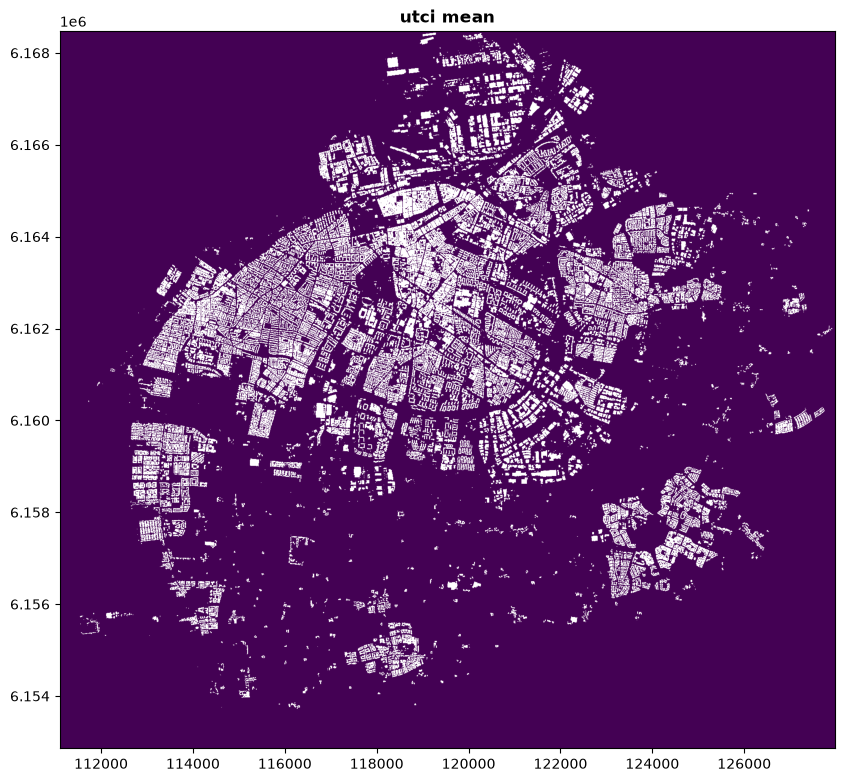

In [6]:
# How to open and display TIFF
with rasterio.open(r'data\processed\valid_target_10m.tif') as src:
    print(src)
    fig, ax = plt.subplots(figsize=(10,10))
    show(src, ax=ax, title="utci mean")
    plt.show()

In [11]:
feature_paths = [
    r'data\processed\building_presence_10m.tif',
    r'data\processed\canopy_presence_10m.tif',
    r'data\processed\landuse_bostadsbebyggelse_10m.tif',
    r'data\processed\landuse_h_rdgjord_mark_10m.tif',
    r'data\processed\landuse_industrimark_10m.tif',
    r'data\processed\landuse_kyrkog_rd_10m.tif',
    r'data\processed\landuse_naturomr_de_10m.tif',
    r'data\processed\landuse_park-_gr_nomr_de_10m.tif',
    r'data\processed\landuse_ppen_mark_10m.tif',
    r'data\processed\landuse_s_rskilda_fritidsomr_den_10m.tif',
    r'data\processed\landuse_tomtmark_10m.tif',
    r'data\processed\landuse_vatten_10m.tif'
]

feature_names = [
    "Buildings",
    "Tree_canopy",
    "Residential",
    "Paved_surface",
    "Industrial",
    "Cemetery",
    "Natural",
    "Park/green",
    "Open",
    "Recreation",
    "Plots",
    "Water",
]

target_path = r'data\processed\utci_mean_10m.tif'

In [17]:
# 1. Load target and initialize mask
with rasterio.open(target_path) as src:
    y_raw = src.read(1)
    target_nodata = src.nodata
    transform = src.transform
    height, width = src.shape

valid_mask = ~np.isnan(y_raw)
if target_nodata is not None and not np.isnan(target_nodata):
    valid_mask &= (y_raw != target_nodata)

# 2. Load features
X_raw_list = []
for path in feature_paths:
    with rasterio.open(path) as src:
        feat = src.read(1)
        valid_mask &= ~np.isnan(feat)
        X_raw_list.append(feat)

# 3. Generate geographic coordinates (returns 1D arrays)
cols, rows = np.meshgrid(np.arange(width), np.arange(height))
easting, northing = rasterio.transform.xy(transform, rows, cols, offset='center')
easting = np.array(easting)
northing = np.array(nortexting if 'nortexting' in locals() else northing) # just northing

# 4. Define your hold-out bounding box
holdout_box = {
    'xmin': 122000,
    'xmax': 127200,
    'ymin': 6155800,
    'ymax': 6165300
}

# Create the spatial holdout mask in 1D
spatial_holdout_mask = (
    (easting >= holdout_box['xmin']) & (easting <= holdout_box['xmax']) &
    (northing >= holdout_box['ymin']) & (northing <= holdout_box['ymax'])
)

# 5. Flatten valid_mask to 1D and combine with the spatial mask
valid_mask_flat = valid_mask.flatten()
train_mask = valid_mask_flat & (~spatial_holdout_mask)
test_mask = valid_mask_flat & spatial_holdout_mask

# 6. Flatten target and features, then apply masks
y_flat = y_raw.flatten()
y_train = y_flat[train_mask]
y_test = y_flat[test_mask]

X_train = pd.DataFrame(
    np.column_stack([feat.flatten()[train_mask] for feat in X_raw_list]),
    columns=feature_names
)

X_test = pd.DataFrame(
    np.column_stack([feat.flatten()[test_mask] for feat in X_raw_list]),
    columns=feature_names
)

print(f"Training samples: {len(X_train)}")
print(f"Test samples (Hold-out): {len(X_test)}")

Training samples: 1888040
Test samples (Hold-out): 424556


In [18]:
# 6. Scale, Fit, and Evaluate
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = ElasticNetCV(
    l1_ratio=[0.1, 0.5, 0.7, 0.9, 1.0],
    cv=5,
    random_state=42,
    n_jobs=-1
)
model.fit(X_train_scaled, y_train)

# Evaluate on the unseen spatial hold-out area
y_pred = model.predict(X_test_scaled)
print(f"\nTest R2 Score: {r2_score(y_test, y_pred):.3f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.3f}")


Test R2 Score: 0.574
Test RMSE: 1.366


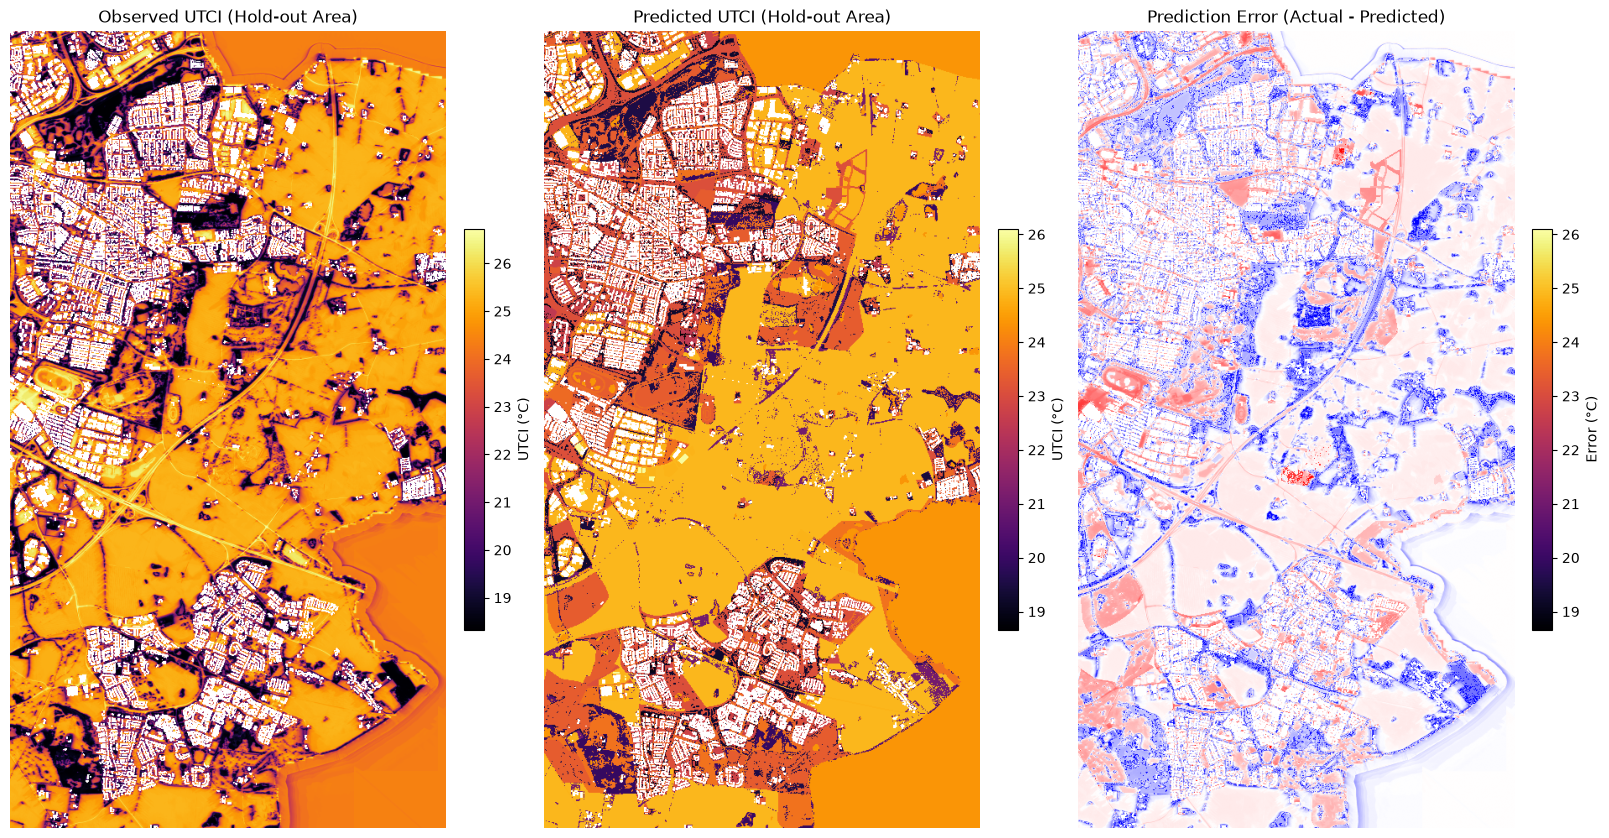

In [27]:
import matplotlib.pyplot as plt

# 1. Initialize full 2D grids filled with NaNs for the whole raster area
obs_grid = np.full((height, width), np.nan)
pred_grid = np.full((height, width), np.nan)
error_grid = np.full((height, width), np.nan)


# 2. Calculate errors for the test set (Actual - Predicted)
y_errors = y_test - y_pred

# 3. Map the test predictions and errors back into their exact 2D pixel locations
# (test_mask is 1D, so we map it back to the 2D grid using the valid 2D test indices)
test_indices_2d = np.where(test_mask.reshape(height, width))
obs_grid[test_indices_2d] = y_test
pred_grid[test_indices_2d] = y_pred
error_grid[test_indices_2d] = y_errors

# 4. Crop to the hold-out region so the plotted data fills the figure
rows, cols = test_indices_2d
row_min, row_max = rows.min(), rows.max() + 1
col_min, col_max = cols.min(), cols.max() + 1
obs_crop = obs_grid[row_min:row_max, col_min:col_max]
pred_crop = pred_grid[row_min:row_max, col_min:col_max]
error_crop = error_grid[row_min:row_max, col_min:col_max]

fig, axes = plt.subplots(1, 3, figsize=(16, 10), constrained_layout=True)

# Plot Observed UTCI on the hold-out area
im1 = axes[0].imshow(obs_crop, cmap='inferno')
axes[0].set_title("Observed UTCI (Hold-out Area)")
fig.colorbar(im1, ax=axes[0], label="UTCI (°C)", fraction=0.046, pad=0.04)

# Plot Predicted UTCI on the hold-out area
im2 = axes[1].imshow(pred_crop, cmap='inferno')
axes[1].set_title("Predicted UTCI (Hold-out Area)")
fig.colorbar(im2, ax=axes[1], label="UTCI (°C)", fraction=0.046, pad=0.04)

# Plot Error (Residuals)
# Diverging colormap ('coolwarm') is great for errors: 
# Red = Overpredicted, Blue = Underpredicted, White = Perfect
im3 = axes[2].imshow(error_crop, cmap='bwr', vmin=-5, vmax=5)
axes[2].set_title("Prediction Error (Actual - Predicted)")
fig.colorbar(im2, ax=axes[2], label="Error (°C)", fraction=0.046, pad=0.04)


for ax in axes:
    ax.axis('off')
plt.show()